<a href="https://colab.research.google.com/github/Durga2924/CLA-2-TASK-2-FLA/blob/main/FLA_TASK_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FINITE AUTOMATA FOR REAL-TIME INPUT VALIDATION

APPLICATION 1: ATM PIN VALIDATION

APPLICATION 1B: ATM CARD LOCK

APPLICATION 2: PASSWORD VALIDATION

APPLICATION 3: EMAIL FORMAT VALIDATION

TESTING ALL THREE APPLICATIONS


,Application,Input,Expected,Actual,Status
0,ATM PIN,4821,ACCEPTED,ACCEPT,PASS
1,ATM PIN,0000,ACCEPTED,ACCEPT,PASS
2,ATM PIN,9375,ACCEPTED,ACCEPT,PASS
3,ATM PIN,1234,ACCEPTED,ACCEPT,PASS
4,ATM PIN,0042,ACCEPTED,ACCEPT,PASS
5,ATM PIN,482,REJECTED,REJECT,PASS
6,ATM PIN,48211,REJECTED,REJECT,PASS
7,ATM PIN,48a1,REJECTED,REJECT,PASS
8,ATM PIN,12 34,REJECTED,REJECT,PASS
9,ATM PIN,123,REJECTED,REJECT,PASS



TOTAL TEST CASES: 30
PASSED: 30
FAILED: 0

APPLICATION-WISE TEST SUMMARY


Status,PASS
Application,
ATM PIN,10
Email,10
Password,10


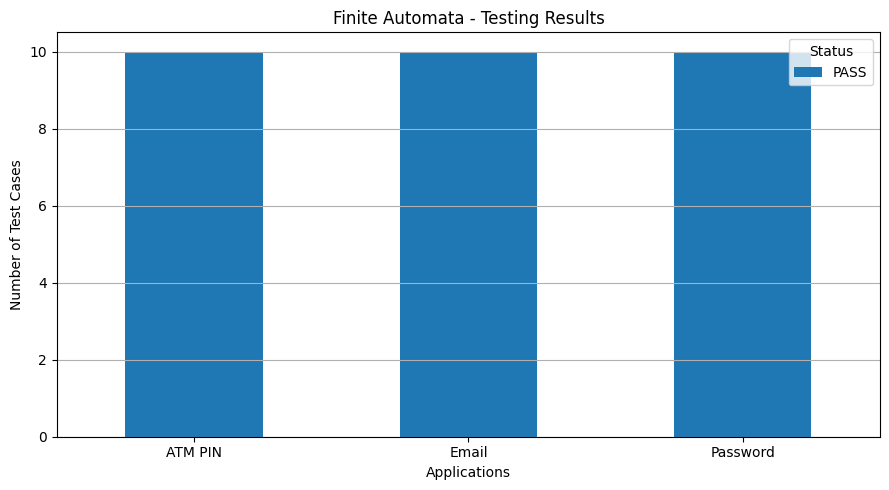

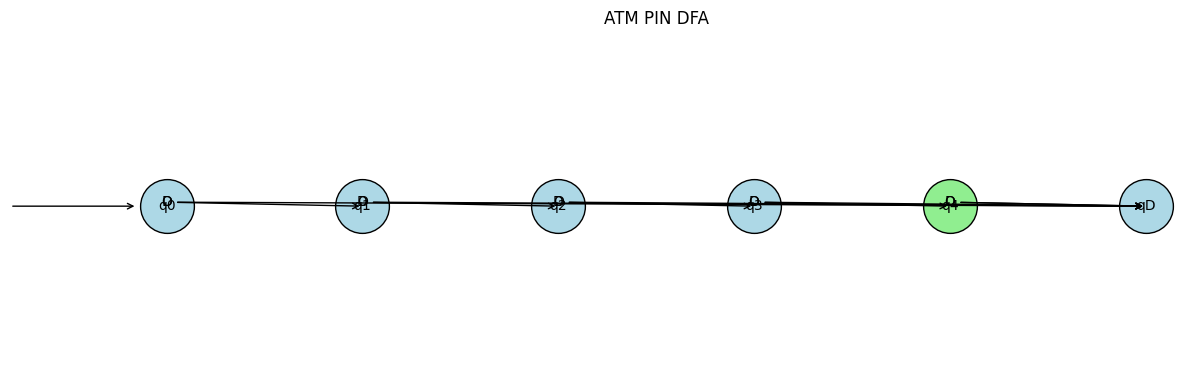

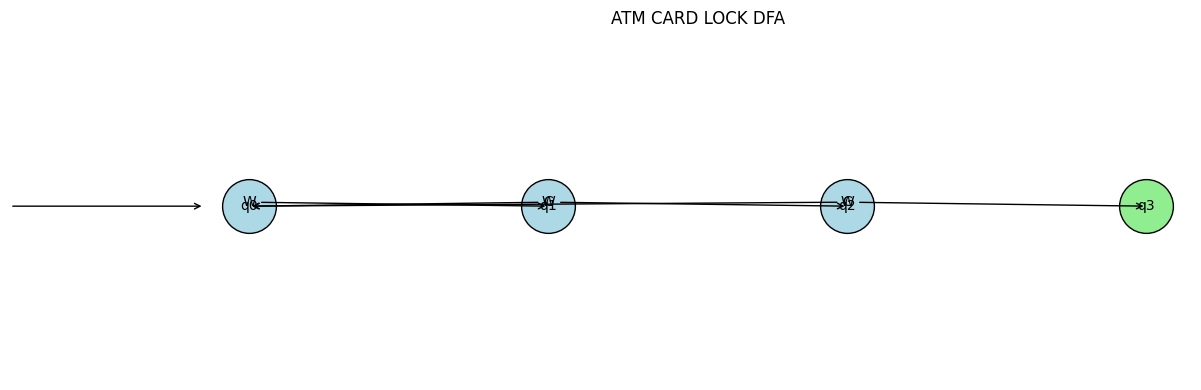

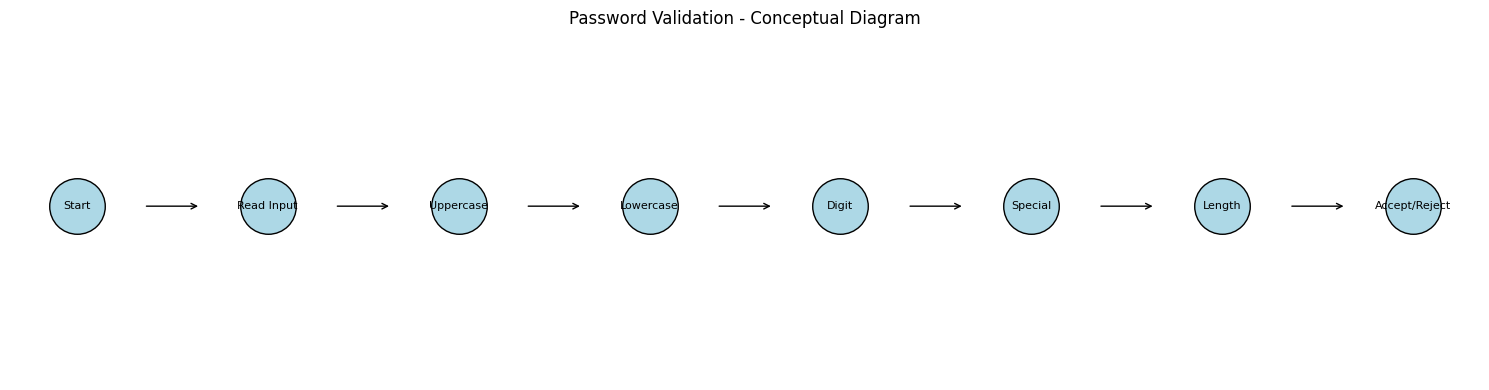

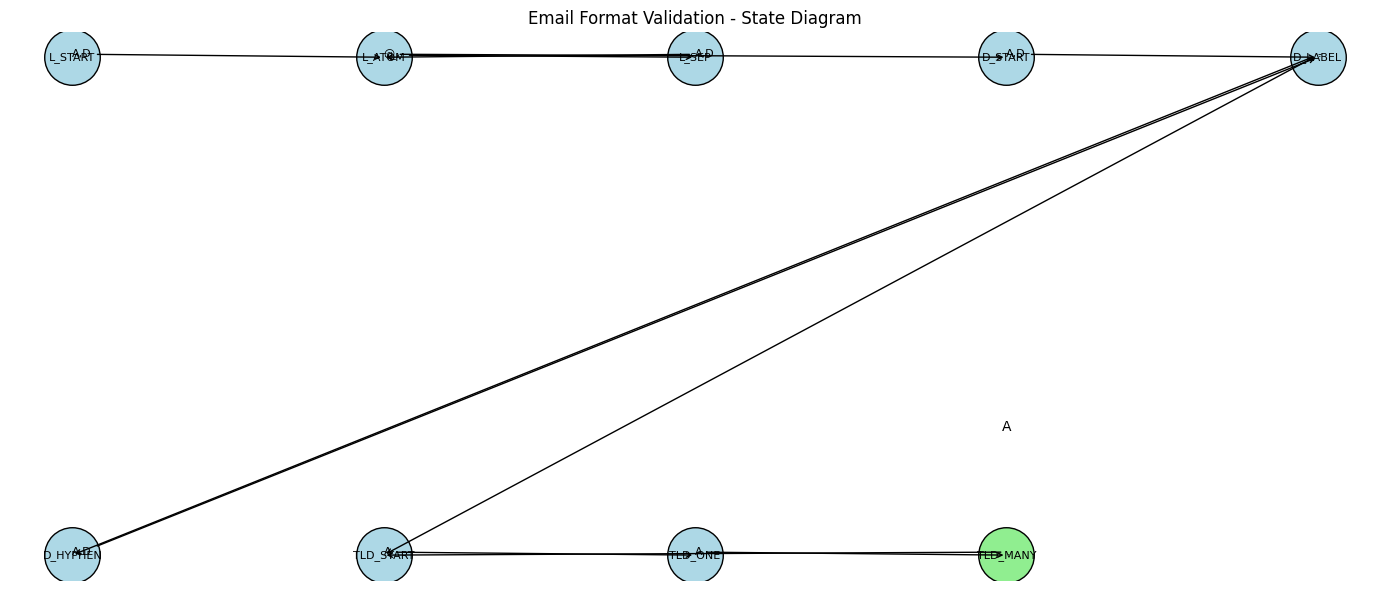


CUSTOM INPUT VALIDATION
Enter ATM PIN: 1234
Enter Password: d@12345
Enter Email: du@gmail.com

YOUR VALIDATION RESULTS
ATM PIN: ACCEPTED
PASSWORD: REJECTED
EMAIL: ACCEPTED

CARD LOCK DEMONSTRATION
Input Events: WWCWW
Card Status: ACTIVE
Transition Trace: [('W', 'q1'), ('W', 'q2'), ('C', 'q0'), ('W', 'q1'), ('W', 'q2')]

PROJECT CONCLUSION

This project demonstrates finite automata in real-time
input validation.

1. ATM PIN DFA checks exactly four digits.
2. Card Lock DFA detects three consecutive wrong attempts.
3. Password DFA checks length and character requirements.
4. Email automaton checks a practical email syntax.

Automata validate input format, but they do not verify
real bank credentials, mailbox existence or leaked passwords.

The project demonstrates the importance of DFA and NFA
in practical input validation and formal language theory.

TASK 2 EXECUTION COMPLETED


In [1]:

# ================================================================
# TASK 2: FINITE AUTOMATA FOR REAL-TIME INPUT VALIDATION
# Course: 21CSC301T - FORMAL LANGUAGE AND AUTOMATA
# Student: Dande Durga Prasad
# Register Number: RA2411026050066
# ================================================================

import string
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

print("=" * 70)
print("FINITE AUTOMATA FOR REAL-TIME INPUT VALIDATION")
print("=" * 70)

# ================================================================
# 1. GENERAL DFA CLASS
# ================================================================

class DFA:

    def __init__(self, states, alphabet, transitions,
                 start_state, final_states):

        self.states = states
        self.alphabet = alphabet
        self.transitions = transitions
        self.start_state = start_state
        self.final_states = final_states

    def validate(self, input_string):

        current_state = self.start_state
        trace = []

        for symbol in input_string:

            next_state = self.transitions.get(
                (current_state, symbol), "qD"
            )

            trace.append(
                (current_state, symbol, next_state)
            )

            current_state = next_state

        accepted = current_state in self.final_states

        return accepted, current_state, trace


# ================================================================
# 2. APPLICATION 1: ATM PIN VALIDATION USING DFA
# ================================================================

print("\nAPPLICATION 1: ATM PIN VALIDATION")

pin_states = ["q0", "q1", "q2", "q3", "q4", "qD"]

pin_alphabet = ["D", "O"]

pin_transitions = {}

for i in range(4):
    pin_transitions[(f"q{i}", "D")] = f"q{i+1}"

for state in pin_states[:-1]:
    pin_transitions[(state, "O")] = "qD"

pin_transitions[("q4", "D")] = "qD"
pin_transitions[("q4", "O")] = "qD"
pin_transitions[("qD", "D")] = "qD"
pin_transitions[("qD", "O")] = "qD"

pin_dfa = DFA(
    pin_states,
    pin_alphabet,
    pin_transitions,
    "q0",
    ["q4"]
)

def validate_pin(pin):

    classified = ""

    for char in pin:

        if char in string.digits:
            classified += "D"
        else:
            classified += "O"

    return pin_dfa.validate(classified)


# ================================================================
# 3. APPLICATION 1B: ATM CARD LOCK DFA
# ================================================================

print("\nAPPLICATION 1B: ATM CARD LOCK")

card_transitions = {

    ("q0", "C"): "q0",
    ("q0", "W"): "q1",

    ("q1", "C"): "q0",
    ("q1", "W"): "q2",

    ("q2", "C"): "q0",
    ("q2", "W"): "q3",

    ("q3", "C"): "q3",
    ("q3", "W"): "q3"
}

def card_lock(events):

    state = "q0"
    trace = []

    for event in events:

        if event not in ["C", "W"]:
            raise ValueError("Use only C and W")

        state = card_transitions[(state, event)]

        trace.append((event, state))

    return state == "q3", trace


# ================================================================
# 4. APPLICATION 2: PASSWORD POLICY VALIDATION
# ================================================================

print("\nAPPLICATION 2: PASSWORD VALIDATION")

# Product DFA state:
# (length, mask)
# U = 1, L = 2, D = 4, S = 8
# Accepting mask = 15

def password_classifier(char):

    if not char.isascii():
        return "O"

    if char.isupper():
        return "U"

    elif char.islower():
        return "L"

    elif char.isdigit():
        return "D"

    else:
        return "S"


def validate_password(password):

    length = 0
    mask = 0
    trace = []

    for char in password:

        category = password_classifier(char)

        next_length = length
        next_mask = mask

        if length >= 16 or category == "O":

            next_length = 17

        else:

            next_length = length + 1

            if category == "U":
                next_mask |= 1

            elif category == "L":
                next_mask |= 2

            elif category == "D":
                next_mask |= 4

            elif category == "S":
                next_mask |= 8

        trace.append(
            (length, mask, char, next_length, next_mask)
        )

        length = next_length
        mask = next_mask

    accepted = (
        8 <= length <= 16 and mask == 15
    )

    return accepted, length, mask, trace


# ================================================================
# 5. APPLICATION 3: EMAIL FORMAT VALIDATION
# ================================================================

print("\nAPPLICATION 3: EMAIL FORMAT VALIDATION")

# Practical email syntax automaton
# Local part: alphanumeric groups separated by . _ -
# Domain: labels with optional internal hyphens
# TLD: at least two alphabetic characters

EMAIL_TRANSITIONS = {

    ("L_START", "A"): "L_ATOM",
    ("L_START", "D"): "L_ATOM",

    ("L_ATOM", "A"): "L_ATOM",
    ("L_ATOM", "D"): "L_ATOM",

    ("L_ATOM", "."): "L_SEP",
    ("L_ATOM", "_"): "L_SEP",
    ("L_ATOM", "-"): "L_SEP",

    ("L_SEP", "A"): "L_ATOM",
    ("L_SEP", "D"): "L_ATOM",

    ("L_ATOM", "@"): "D_START",

    ("D_START", "A"): "D_LABEL",
    ("D_START", "D"): "D_LABEL",

    ("D_LABEL", "A"): "D_LABEL",
    ("D_LABEL", "D"): "D_LABEL",
    ("D_LABEL", "-"): "D_HYPHEN",

    ("D_HYPHEN", "A"): "D_LABEL",
    ("D_HYPHEN", "D"): "D_LABEL",

    ("D_LABEL", "."): "TLD_START",

    ("TLD_START", "A"): "TLD_ONE",

    ("TLD_ONE", "A"): "TLD_MANY",

    ("TLD_MANY", "A"): "TLD_MANY",
    ("TLD_MANY", "."): "TLD_START"
}


def email_classifier(char):

    if char.isascii() and char.isalpha():
        return "A"

    elif char.isascii() and char.isdigit():
        return "D"

    elif char in "._-@":
        return char

    else:
        return "X"


def validate_email(email):

    state = "L_START"
    trace = []

    for char in email:

        symbol = email_classifier(char)

        next_state = EMAIL_TRANSITIONS.get(
            (state, symbol), "qD"
        )

        trace.append(
            (state, char, next_state)
        )

        state = next_state

    accepted = state == "TLD_MANY"

    return accepted, state, trace


# ================================================================
# 6. TEST CASES
# ================================================================

print("\n" + "=" * 70)
print("TESTING ALL THREE APPLICATIONS")
print("=" * 70)

test_data = {

    "ATM PIN": {

        "Accepted": [
            "4821", "0000", "9375",
            "1234", "0042"
        ],

        "Rejected": [
            "482", "48211", "48a1",
            "12 34", "123"
        ]
    },

    "Password": {

        "Accepted": [
            "Srm@2026",
            "Trichy#Aiml5",
            "aB3$efgh",
            "P@ssw0rdX",
            "Q1w2e3r4!T"
        ],

        "Rejected": [
            "srm@2026",
            "SRM@2026",
            "Srm@Trichy",
            "Srm20266",
            "Abcdefgh1!xyzABC9"
        ]
    },

    "Email": {

        "Accepted": [
            "student@srmist.edu.in",
            "ra2411026050066@srmist.edu.in",
            "srm_student@gmail.com",
            "a-b.c@my-site.co",
            "x@y.io"
        ],

        "Rejected": [
            ".student@gmail.com",
            "student..one@gmail.com",
            "student@-srm.in",
            "student@srm.c0m",
            "student@@gmail.com"
        ]
    }
}


all_results = []

for application, categories in test_data.items():

    for expected, values in categories.items():

        for value in values:

            if application == "ATM PIN":
                actual = validate_pin(value)[0]

            elif application == "Password":
                actual = validate_password(value)[0]

            else:
                actual = validate_email(value)[0]

            expected_value = expected == "Accepted"

            status = (
                "PASS" if actual == expected_value else "FAIL"
            )

            all_results.append({

                "Application": application,
                "Input": value,
                "Expected": expected.upper(),
                "Actual": "ACCEPT" if actual else "REJECT",
                "Status": status

            })


results_df = pd.DataFrame(all_results)

display(results_df)

print("\nTOTAL TEST CASES:", len(results_df))
print("PASSED:", (results_df["Status"] == "PASS").sum())
print("FAILED:", (results_df["Status"] == "FAIL").sum())


# ================================================================
# 7. AUTOMATIC TESTING SUMMARY
# ================================================================

print("\nAPPLICATION-WISE TEST SUMMARY")

summary = results_df.groupby(
    ["Application", "Status"]
).size().unstack(fill_value=0)

display(summary)


# ================================================================
# 8. GRAPH: TEST RESULTS
# ================================================================

summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Finite Automata - Testing Results")
plt.xlabel("Applications")
plt.ylabel("Number of Test Cases")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# ================================================================
# 9. ATM PIN DFA STATE DIAGRAM
# ================================================================

def draw_linear_dfa(title, states, transitions,
                    start_state, final_states):

    plt.figure(figsize=(12, 4))

    positions = {
        state: (index, 0)
        for index, state in enumerate(states)
    }

    for state in states:

        x, y = positions[state]

        color = (
            "lightgreen"
            if state in final_states
            else "lightblue"
        )

        plt.scatter(
            x, y,
            s=1500,
            color=color,
            edgecolors="black"
        )

        plt.text(
            x, y, state,
            ha="center",
            va="center"
        )

    for (source, symbol), destination in transitions.items():

        x1, y1 = positions[source]
        x2, y2 = positions[destination]

        if source == destination:
            plt.annotate(
                symbol,
                (x1, y1 + 0.25),
                ha="center"
            )

        else:
            plt.annotate(
                symbol,
                xy=(x2, y2),
                xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->"),
                ha="center"
            )

    sx, sy = positions[start_state]

    plt.annotate(
        "",
        xy=(sx - 0.15, sy),
        xytext=(sx - 0.8, sy),
        arrowprops=dict(arrowstyle="->")
    )

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


draw_linear_dfa(
    "ATM PIN DFA",
    pin_states,
    pin_transitions,
    "q0",
    ["q4"]
)


# ================================================================
# 10. CARD LOCK DFA DIAGRAM
# ================================================================

card_states = ["q0", "q1", "q2", "q3"]

card_graph_transitions = {

    ("q0", "C"): "q0",
    ("q0", "W"): "q1",
    ("q1", "C"): "q0",
    ("q1", "W"): "q2",
    ("q2", "C"): "q0",
    ("q2", "W"): "q3",
    ("q3", "C"): "q3",
    ("q3", "W"): "q3"
}

draw_linear_dfa(
    "ATM CARD LOCK DFA",
    card_states,
    card_graph_transitions,
    "q0",
    ["q3"]
)


# ================================================================
# 11. PASSWORD DFA CONCEPTUAL DIAGRAM
# ================================================================

password_stages = [
    "Start",
    "Read Input",
    "Uppercase",
    "Lowercase",
    "Digit",
    "Special",
    "Length",
    "Accept/Reject"
]

plt.figure(figsize=(15, 4))

for i, stage in enumerate(password_stages):

    plt.scatter(
        i, 0,
        s=1600,
        color="lightblue",
        edgecolors="black"
    )

    plt.text(
        i, 0,
        stage,
        ha="center",
        va="center",
        fontsize=8
    )

    if i < len(password_stages) - 1:

        plt.annotate(
            "",
            xy=(i + 0.65, 0),
            xytext=(i + 0.35, 0),
            arrowprops=dict(arrowstyle="->")
        )

plt.title("Password Validation - Conceptual Diagram")
plt.axis("off")
plt.tight_layout()
plt.show()


# ================================================================
# 12. EMAIL AUTOMATON STATE DIAGRAM
# ================================================================

email_states = [
    "L_START",
    "L_ATOM",
    "L_SEP",
    "D_START",
    "D_LABEL",
    "D_HYPHEN",
    "TLD_START",
    "TLD_ONE",
    "TLD_MANY"
]

email_edges = [

    ("L_START", "L_ATOM", "A,D"),
    ("L_ATOM", "L_SEP", ".,_,-"),
    ("L_SEP", "L_ATOM", "A,D"),
    ("L_ATOM", "D_START", "@"),
    ("D_START", "D_LABEL", "A,D"),
    ("D_LABEL", "D_HYPHEN", "-"),
    ("D_HYPHEN", "D_LABEL", "A,D"),
    ("D_LABEL", "TLD_START", "."),
    ("TLD_START", "TLD_ONE", "A"),
    ("TLD_ONE", "TLD_MANY", "A"),
    ("TLD_MANY", "TLD_MANY", "A"),
    ("TLD_MANY", "TLD_START", ".")

]

plt.figure(figsize=(14, 6))

positions = {
    state: (i % 5, -(i // 5))
    for i, state in enumerate(email_states)
}

for state, (x, y) in positions.items():

    color = (
        "lightgreen"
        if state == "TLD_MANY"
        else "lightblue"
    )

    plt.scatter(
        x, y,
        s=1600,
        color=color,
        edgecolors="black"
    )

    plt.text(
        x, y, state,
        ha="center",
        va="center",
        fontsize=8
    )

for source, destination, label in email_edges:

    x1, y1 = positions[source]
    x2, y2 = positions[destination]

    if source == destination:
        plt.annotate(
            label,
            (x1, y1 + 0.25),
            ha="center"
        )
    else:
        plt.annotate(
            label,
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops=dict(arrowstyle="->"),
            fontsize=8
        )

plt.title("Email Format Validation - State Diagram")
plt.axis("off")
plt.tight_layout()
plt.show()


# ================================================================
# 13. INDIVIDUAL INPUT VALIDATION
# ================================================================

print("\nCUSTOM INPUT VALIDATION")

pin_input = input("Enter ATM PIN: ")
password_input = input("Enter Password: ")
email_input = input("Enter Email: ")

print("\nYOUR VALIDATION RESULTS")

print(
    "ATM PIN:",
    "ACCEPTED" if validate_pin(pin_input)[0] else "REJECTED"
)

print(
    "PASSWORD:",
    "ACCEPTED" if validate_password(password_input)[0] else "REJECTED"
)

print(
    "EMAIL:",
    "ACCEPTED" if validate_email(email_input)[0] else "REJECTED"
)


# ================================================================
# 14. CARD LOCK TEST
# ================================================================

print("\nCARD LOCK DEMONSTRATION")

events = "WWCWW"

locked, card_trace = card_lock(events)

print("Input Events:", events)
print("Card Status:", "LOCKED" if locked else "ACTIVE")
print("Transition Trace:", card_trace)


# ================================================================
# 15. PROJECT CONCLUSION
# ================================================================

print("\n" + "=" * 70)
print("PROJECT CONCLUSION")
print("=" * 70)

print("""
This project demonstrates finite automata in real-time
input validation.

1. ATM PIN DFA checks exactly four digits.
2. Card Lock DFA detects three consecutive wrong attempts.
3. Password DFA checks length and character requirements.
4. Email automaton checks a practical email syntax.

Automata validate input format, but they do not verify
real bank credentials, mailbox existence or leaked passwords.

The project demonstrates the importance of DFA and NFA
in practical input validation and formal language theory.
""")

print("=" * 70)
print("TASK 2 EXECUTION COMPLETED")
print("=" * 70)
